<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/sessions/Session05_logistic_regression_and_metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۵: رگرسیون لجستیک و معیارهای ارزیابی طبقه‌بندی

### اهداف این جلسه

- درک رگرسیون لجستیک: تابع سیگموید، احتمال و مرز تصمیم
- آشنایی با تابع هزینهٔ آنتروپی متقاطع (Log Loss) و پیاده‌سازی از صفر
- معیارهای ارزیابی طبقه‌بندی: ماتریس درهم‌ریختگی، Precision، Recall، F1
- تنظیم **آستانهٔ تصمیم** بر اساس هزینهٔ واقعی خطاها
- منحنی ROC و AUC، منحنی Precision-Recall
- طبقه‌بندی چندکلاسه با Softmax

## ۱. چرا رگرسیون خطی برای طبقه‌بندی مناسب نیست؟

در طبقه‌بندی دودویی، برچسب‌ها ۰ و ۱ هستند و می‌خواهیم **احتمال** تعلق به کلاس ۱ را پیش‌بینی کنیم. رگرسیون خطی خروجی‌ای بین منفی بی‌نهایت تا مثبت بی‌نهایت می‌دهد که نمی‌تواند احتمال باشد، و به داده‌های دور از مرز هم بسیار حساس است.

**رگرسیون لجستیک** خروجی خطی را از تابع **سیگموید (Sigmoid)** عبور می‌دهد تا عددی بین صفر و یک به دست آید:

$$z = \mathbf{w}^\top \mathbf{x} + b \qquad \hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

</div>

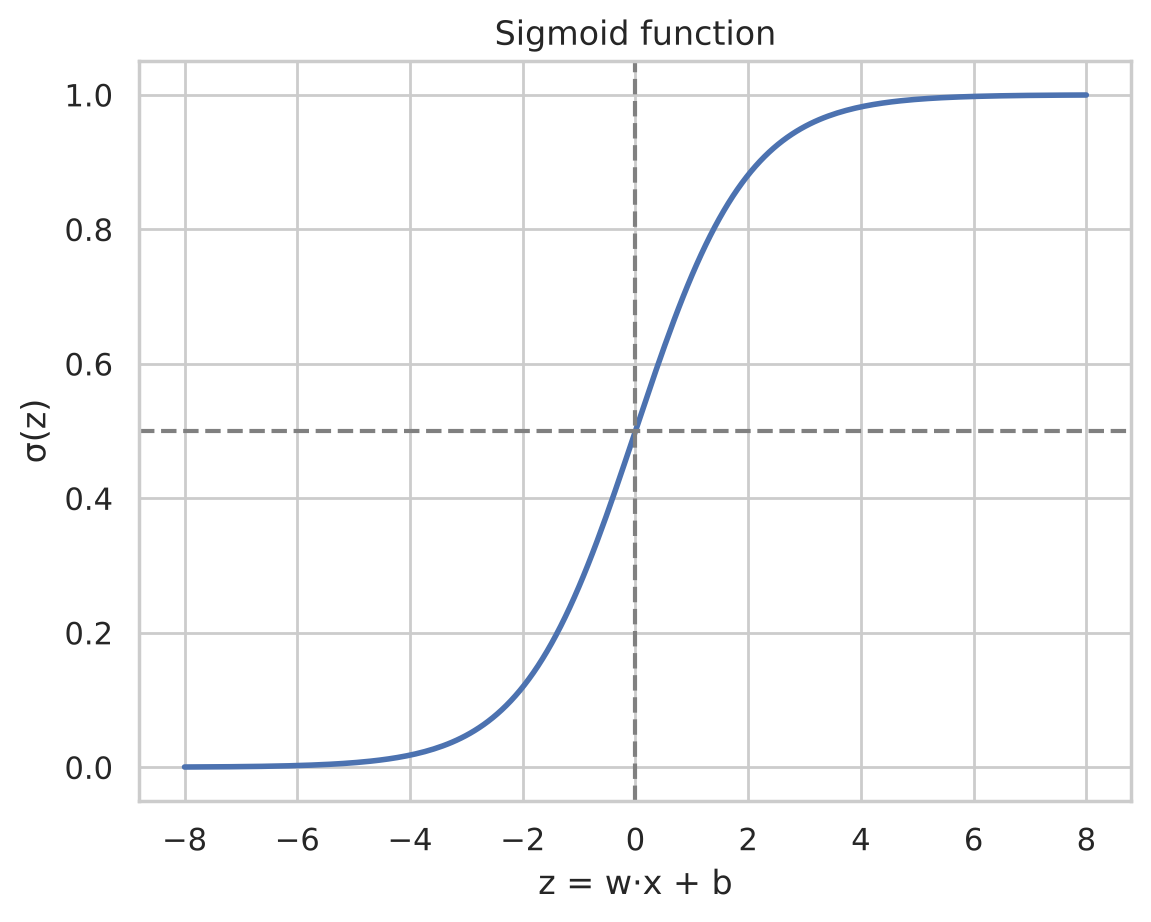

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

z = np.linspace(-8, 8, 200)
plt.plot(z, 1 / (1 + np.exp(-z)), linewidth=2)
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("z = w·x + b")
plt.ylabel("σ(z)")
plt.title("Sigmoid function")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- اگر $z > 0$ باشد، احتمال بیشتر از ۰٫۵ است و کلاس ۱ را پیش‌بینی می‌کنیم.
- **مرز تصمیم (Decision Boundary)** جایی است که $z = 0$؛ یعنی رگرسیون لجستیک یک **طبقه‌بند خطی** است.
- عبارت $z$ همان **لگاریتم نسبت شانس (log-odds)** است: $z = \log\frac{p}{1-p}$. پس هر واحد افزایش در یک ویژگی، log-odds را به اندازهٔ ضریب آن تغییر می‌دهد.

## ۲. تابع هزینه: آنتروپی متقاطع دودویی

اگر از MSE استفاده کنیم، به خاطر سیگموید تابع هزینه محدب نمی‌ماند. به‌جای آن از **آنتروپی متقاطع دودویی (Binary Cross-Entropy / Log Loss)** استفاده می‌کنیم:

$$J(\mathbf{w}, b) = -\frac{1}{m}\sum_{i=1}^{m}\left[y^{(i)} \log \hat{p}^{(i)} + \left(1 - y^{(i)}\right) \log\left(1 - \hat{p}^{(i)}\right)\right]$$

ایده: اگر برچسب واقعی ۱ باشد و مدل احتمال نزدیک صفر بدهد، $-\log \hat{p}$ بسیار بزرگ می‌شود؛ یعنی مدل برای **اطمینان اشتباه** به‌شدت جریمه می‌شود. جالب اینکه گرادیان این تابع دقیقاً همان شکل گرادیان رگرسیون خطی را دارد:

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{m} X^\top (\hat{\mathbf{p}} - \mathbf{y})$$

### ۲.۱ پیاده‌سازی از صفر

</div>

In [2]:
from sklearn.datasets import make_blobs

X_toy, y_toy = make_blobs(n_samples=200, centers=[(-1.5, -1), (1.5, 1)], cluster_std=1.2, random_state=0)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def train_logistic(X, y, lr=0.1, n_iter=2000):
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    losses = []
    for _ in range(n_iter):
        p = sigmoid(X @ w + b)
        losses.append(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))
        w -= lr * X.T @ (p - y) / m
        b -= lr * np.mean(p - y)
    return w, b, losses

w, b, losses = train_logistic(X_toy, y_toy)
accuracy = np.mean((sigmoid(X_toy @ w + b) >= 0.5) == y_toy)
print(f"w = {w.round(3)}, b = {b:.3f}, training accuracy = {accuracy:.3f}")

w = [1.892 1.282], b = 0.012, training accuracy = 0.930


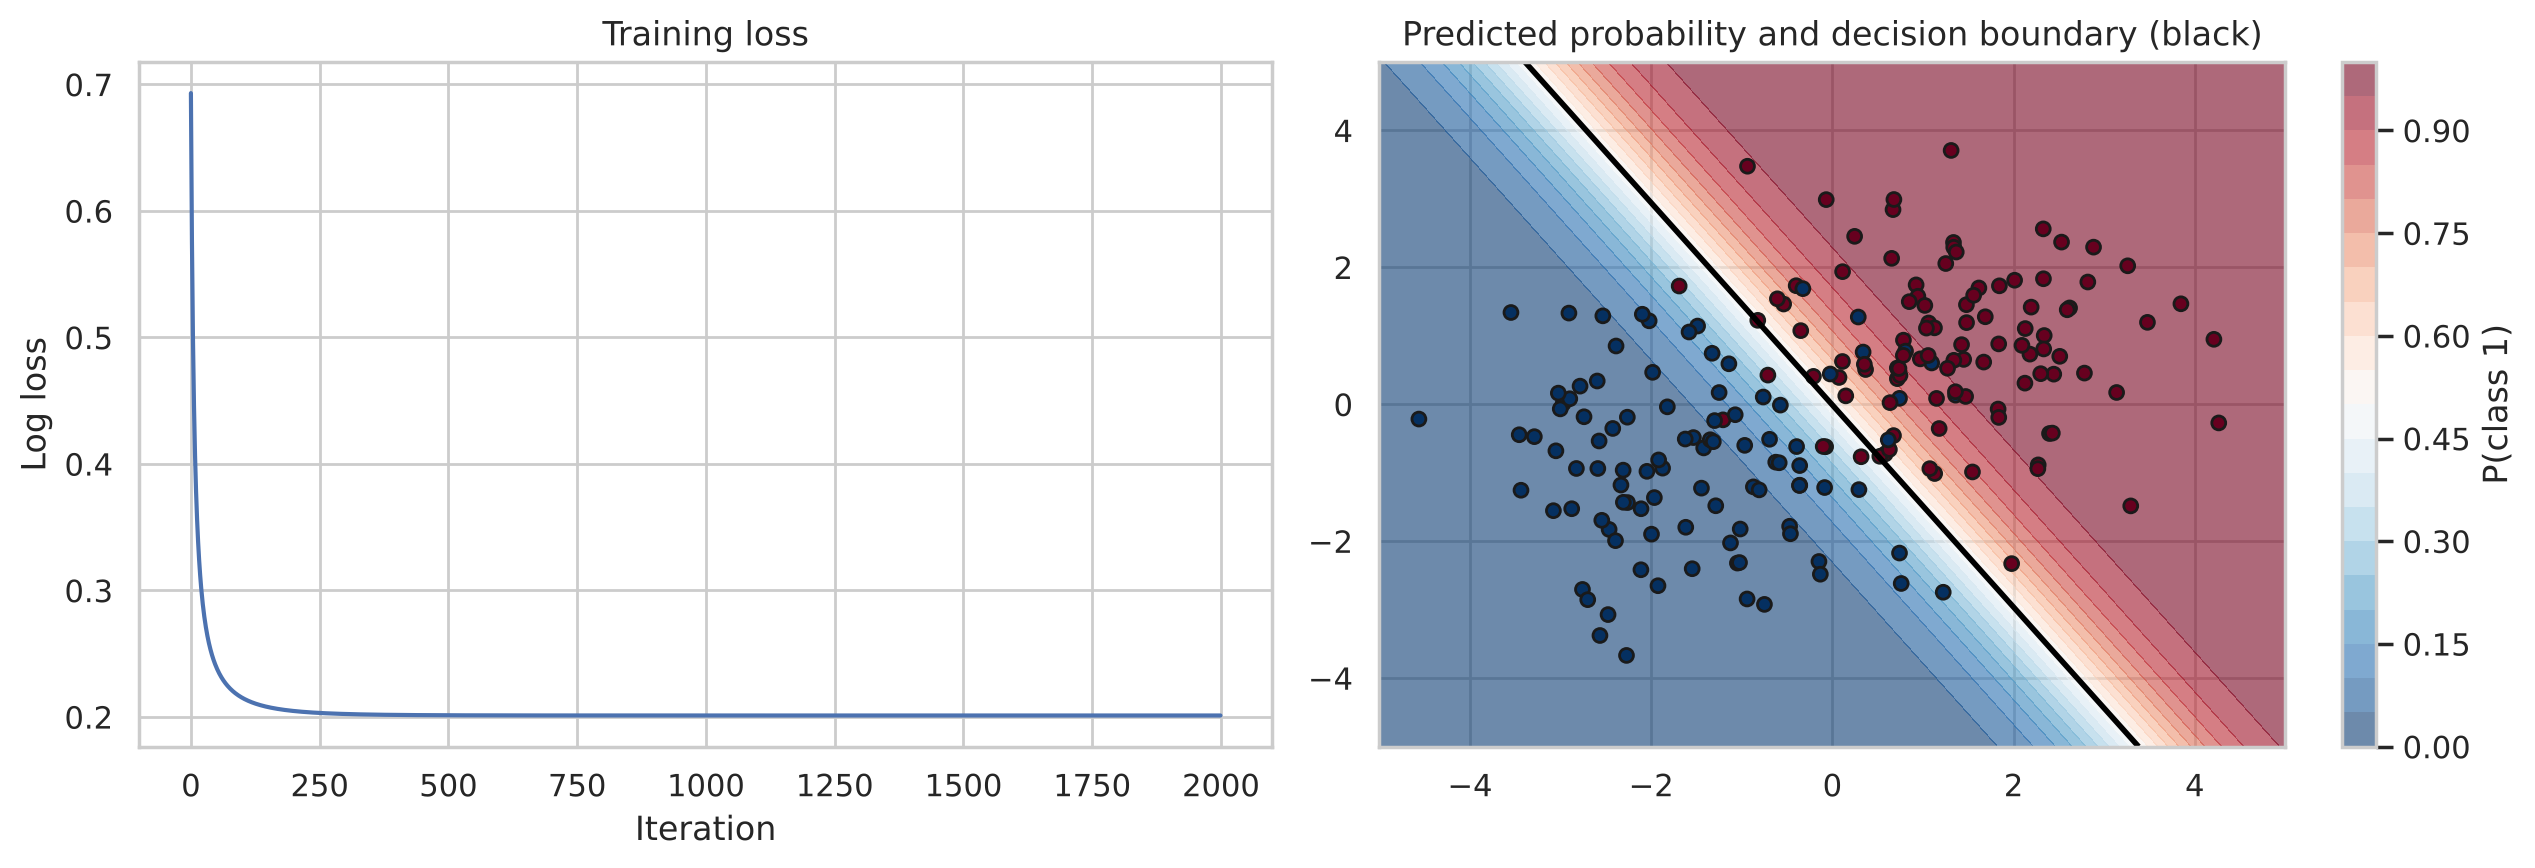

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(losses)
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Log loss")
axes[0].set_title("Training loss")

xx, yy = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-5, 5, 300))
probs = sigmoid(np.c_[xx.ravel(), yy.ravel()] @ w + b).reshape(xx.shape)
cs = axes[1].contourf(xx, yy, probs, levels=20, cmap="RdBu_r", alpha=0.6)
axes[1].contour(xx, yy, probs, levels=[0.5], colors="black", linewidths=2)
axes[1].scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap="RdBu_r", edgecolor="k", s=25)
plt.colorbar(cs, ax=axes[1], label="P(class 1)")
axes[1].set_title("Predicted probability and decision boundary (black)")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

خط سیاه مرز تصمیم ($\hat{p} = 0.5$) است. هرچه از مرز دورتر شویم، مدل مطمئن‌تر می‌شود.

## ۳. مسئلهٔ واقعی: تشخیص سرطان سینه

مجموعه‌دادهٔ **Breast Cancer Wisconsin** شامل ۳۰ ویژگی استخراج‌شده از تصاویر نمونه‌برداری بافت (اندازه، بافت و شکل هستهٔ سلول‌ها) برای ۵۶۹ نمونه است. هدف: تشخیص تومور **بدخیم (malignant)** از **خوش‌خیم (benign)**.

در scikit-learn، کلاس ۰ بدخیم است. چون در پزشکی معمولاً «بیماری» را کلاس **مثبت** می‌نامیم، برچسب‌ها را برعکس می‌کنیم تا ۱ به معنای بدخیم باشد.

</div>

In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = 1 - cancer.target          # 1 = malignant (positive class), 0 = benign

print("Shape:", X.shape)
print(y.value_counts().rename({1: "malignant (1)", 0: "benign (0)"}))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

Shape: (569, 30)
target
benign (0)       357
malignant (1)    212
Name: count, dtype: int64


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]
print(f"Accuracy: {log_reg.score(X_test, y_test):.3f}")
print("First 5 predicted probabilities of malignancy:", y_proba[:5].round(3))

Accuracy: 0.965
First 5 predicted probabilities of malignancy: [0.999 0.004 1.    0.    0.035]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. ماتریس درهم‌ریختگی و معیارهای طبقه‌بندی

دقت حدود ۹۶٪ عالی به نظر می‌رسد، ولی **دقت (accuracy) همهٔ داستان را نمی‌گوید**. در تشخیص سرطان، دو نوع خطا هزینهٔ کاملاً متفاوتی دارند:

| | پیش‌بینی: خوش‌خیم (۰) | پیش‌بینی: بدخیم (۱) |
|---|---|---|
| **واقعی: خوش‌خیم (۰)** | TN (منفی درست) | FP (مثبت کاذب): نگرانی و آزمایش اضافه |
| **واقعی: بدخیم (۱)** | FN (منفی کاذب): **سرطان تشخیص داده نشده!** | TP (مثبت درست) |

</div>

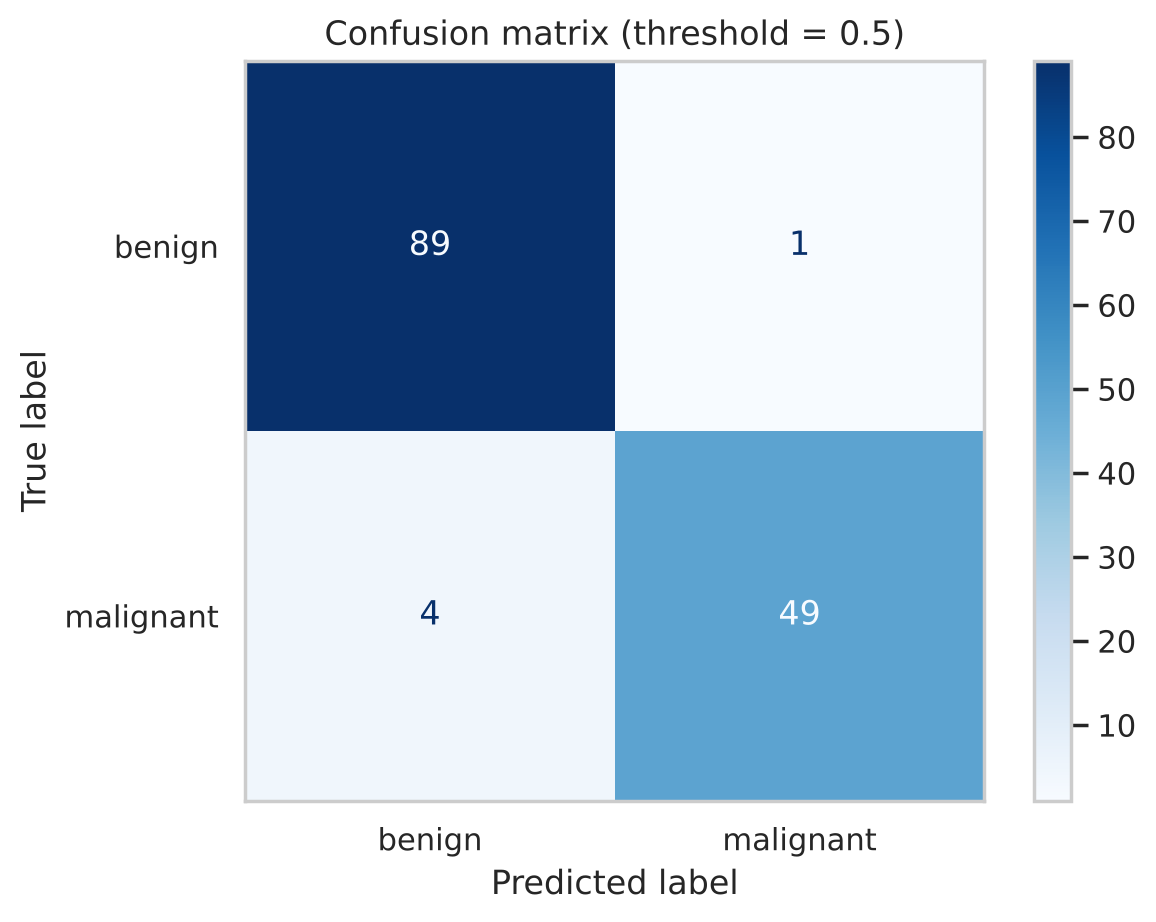

TN=89  FP=1  FN=4  TP=49


In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"]).plot(cmap="Blues")
plt.grid(False)
plt.title("Confusion matrix (threshold = 0.5)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

از روی این چهار عدد، معیارهای اصلی را تعریف می‌کنیم:

$$\text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Precision (دقت مثبت):** از نمونه‌هایی که مدل گفت بدخیم‌اند، چند درصد واقعاً بدخیم بودند؟ «وقتی مدل می‌گوید مثبت، چقدر می‌توان به آن اعتماد کرد؟»
- **Recall (بازیابی یا حساسیت):** از همهٔ نمونه‌های واقعاً بدخیم، مدل چند درصد را پیدا کرد؟ «مدل چه سهمی از موارد مثبت را از دست نمی‌دهد؟»
- **F1:** میانگین هارمونیک این دو؛ وقتی هر دو مهم‌اند.
- **Specificity (ویژگی):** $\frac{TN}{TN + FP}$؛ سهم موارد سالمی که درست سالم تشخیص داده شده‌اند.

</div>

In [7]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["benign", "malignant"], digits=3))

              precision    recall  f1-score   support

      benign      0.957     0.989     0.973        90
   malignant      0.980     0.925     0.951        53

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143



<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### ۴.۱ پارادوکس دقت: چرا accuracy در دادهٔ نامتوازن فریبنده است

فرض کنید بیماری‌ای فقط در ۱٪ افراد وجود دارد. مدلی که **همیشه** بگوید «سالم»، دقت ۹۹٪ دارد ولی حتی یک بیمار را هم پیدا نمی‌کند (Recall صفر). در داده‌های نامتوازن، مثل تشخیص تقلب، بیماری‌های نادر یا ریزش مشتری، **هرگز فقط به accuracy تکیه نکنید.**

</div>

In [8]:
from sklearn.metrics import accuracy_score, recall_score

y_rare = np.array([1] * 10 + [0] * 990)
y_always_healthy = np.zeros(1000, dtype=int)
print(f"Accuracy: {accuracy_score(y_rare, y_always_healthy):.2%}")
print(f"Recall:   {recall_score(y_rare, y_always_healthy):.2%}")

Accuracy: 99.00%
Recall:   0.00%


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. تنظیم آستانهٔ تصمیم

به‌طور پیش‌فرض، اگر احتمال بیشتر از ۰٫۵ باشد کلاس ۱ را پیش‌بینی می‌کنیم. ولی ۰٫۵ عدد مقدسی نیست! در تشخیص سرطان، از دست دادن یک بیمار (FN) بسیار بدتر از یک آزمایش اضافه (FP) است. پس می‌توانیم آستانه را پایین بیاوریم تا Recall بالاتر برود، به قیمت کاهش Precision.

</div>

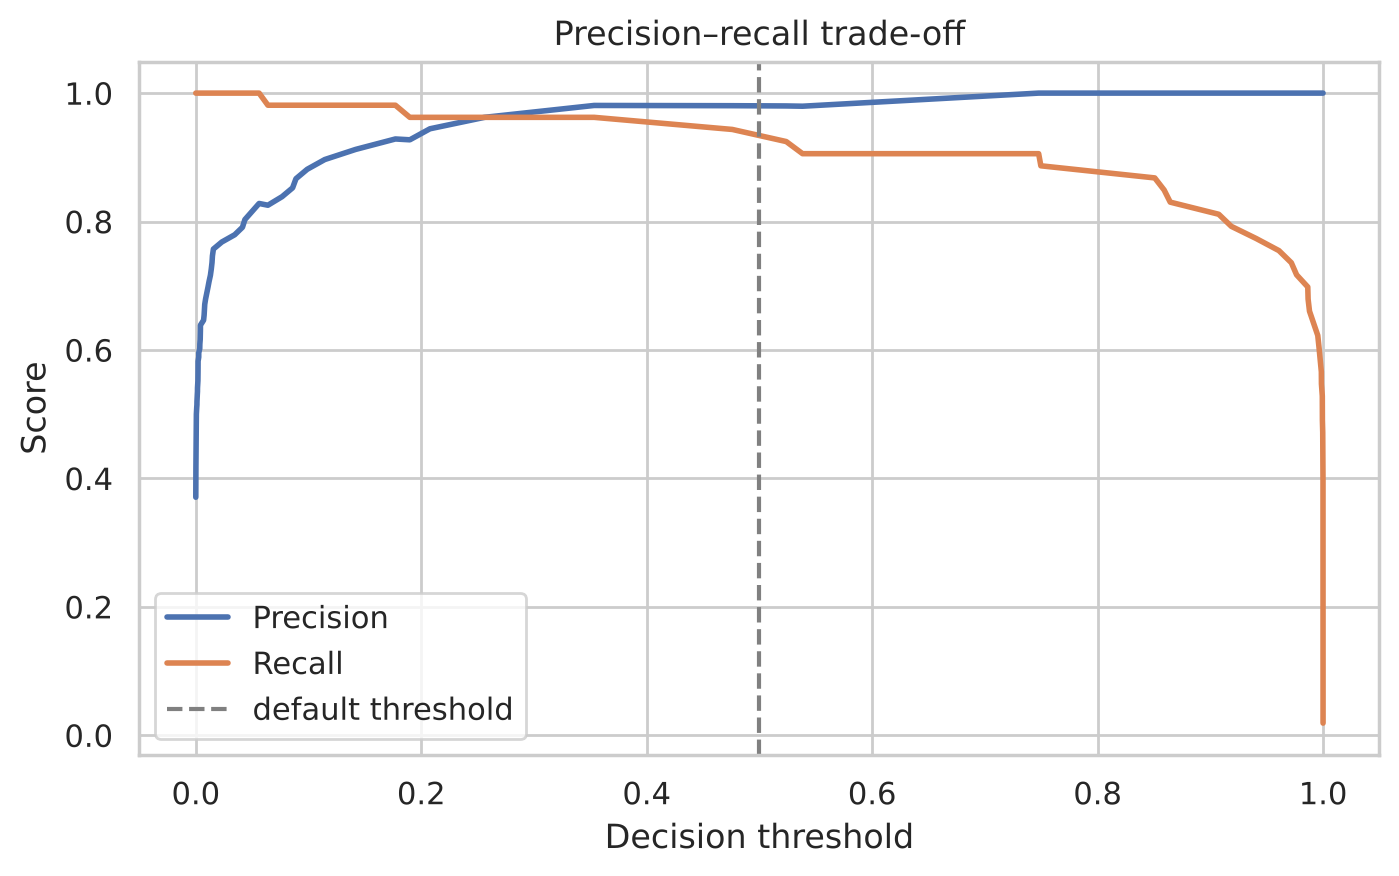

In [9]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, precisions[:-1], label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], label="Recall", linewidth=2)
plt.axvline(0.5, color="gray", linestyle="--", label="default threshold")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision–recall trade-off")
plt.legend()
plt.show()

In [10]:
for threshold in [0.5, 0.3, 0.1]:
    y_pred_t = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    print(f"threshold={threshold:.1f}  FN (missed cancers)={fn}  FP (false alarms)={fp}  "
          f"recall={tp / (tp + fn):.3f}  precision={tp / (tp + fp):.3f}")

threshold=0.5  FN (missed cancers)=4  FP (false alarms)=1  recall=0.925  precision=0.980
threshold=0.3  FN (missed cancers)=2  FP (false alarms)=1  recall=0.962  precision=0.981
threshold=0.1  FN (missed cancers)=1  FP (false alarms)=6  recall=0.981  precision=0.897


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با پایین آوردن آستانه، تعداد سرطان‌های تشخیص‌داده‌نشده کم می‌شود و در عوض هشدارهای کاذب زیاد می‌شوند. **انتخاب آستانه یک تصمیم فنی نیست، تصمیمی کسب‌وکاری یا بالینی است** که به هزینهٔ واقعی هر نوع خطا بستگی دارد.

**نکتهٔ روش‌شناختی:** در پروژهٔ واقعی، آستانه را باید روی دادهٔ **اعتبارسنجی** انتخاب کرد، نه دادهٔ آزمون؛ اینجا برای سادگی آموزش از دادهٔ آزمون استفاده کردیم. scikit-learn برای این کار کلاس `TunedThresholdClassifierCV` را دارد.

## ۶. منحنی ROC و AUC

**منحنی ROC** برای همهٔ آستانه‌های ممکن، نرخ مثبت درست (Recall) را در برابر **نرخ مثبت کاذب** ($FPR = \frac{FP}{FP + TN}$) رسم می‌کند.

- مدل تصادفی روی قطر قرار می‌گیرد.
- مدل کامل از گوشهٔ بالا-چپ عبور می‌کند.
- **AUC (سطح زیر منحنی)** یک عدد بین ۰٫۵ (تصادفی) و ۱ (کامل) است و معنای زیبایی دارد: احتمال اینکه مدل به یک نمونهٔ مثبت تصادفی، امتیاز بالاتری از یک نمونهٔ منفی تصادفی بدهد. AUC به آستانه بستگی ندارد.

</div>

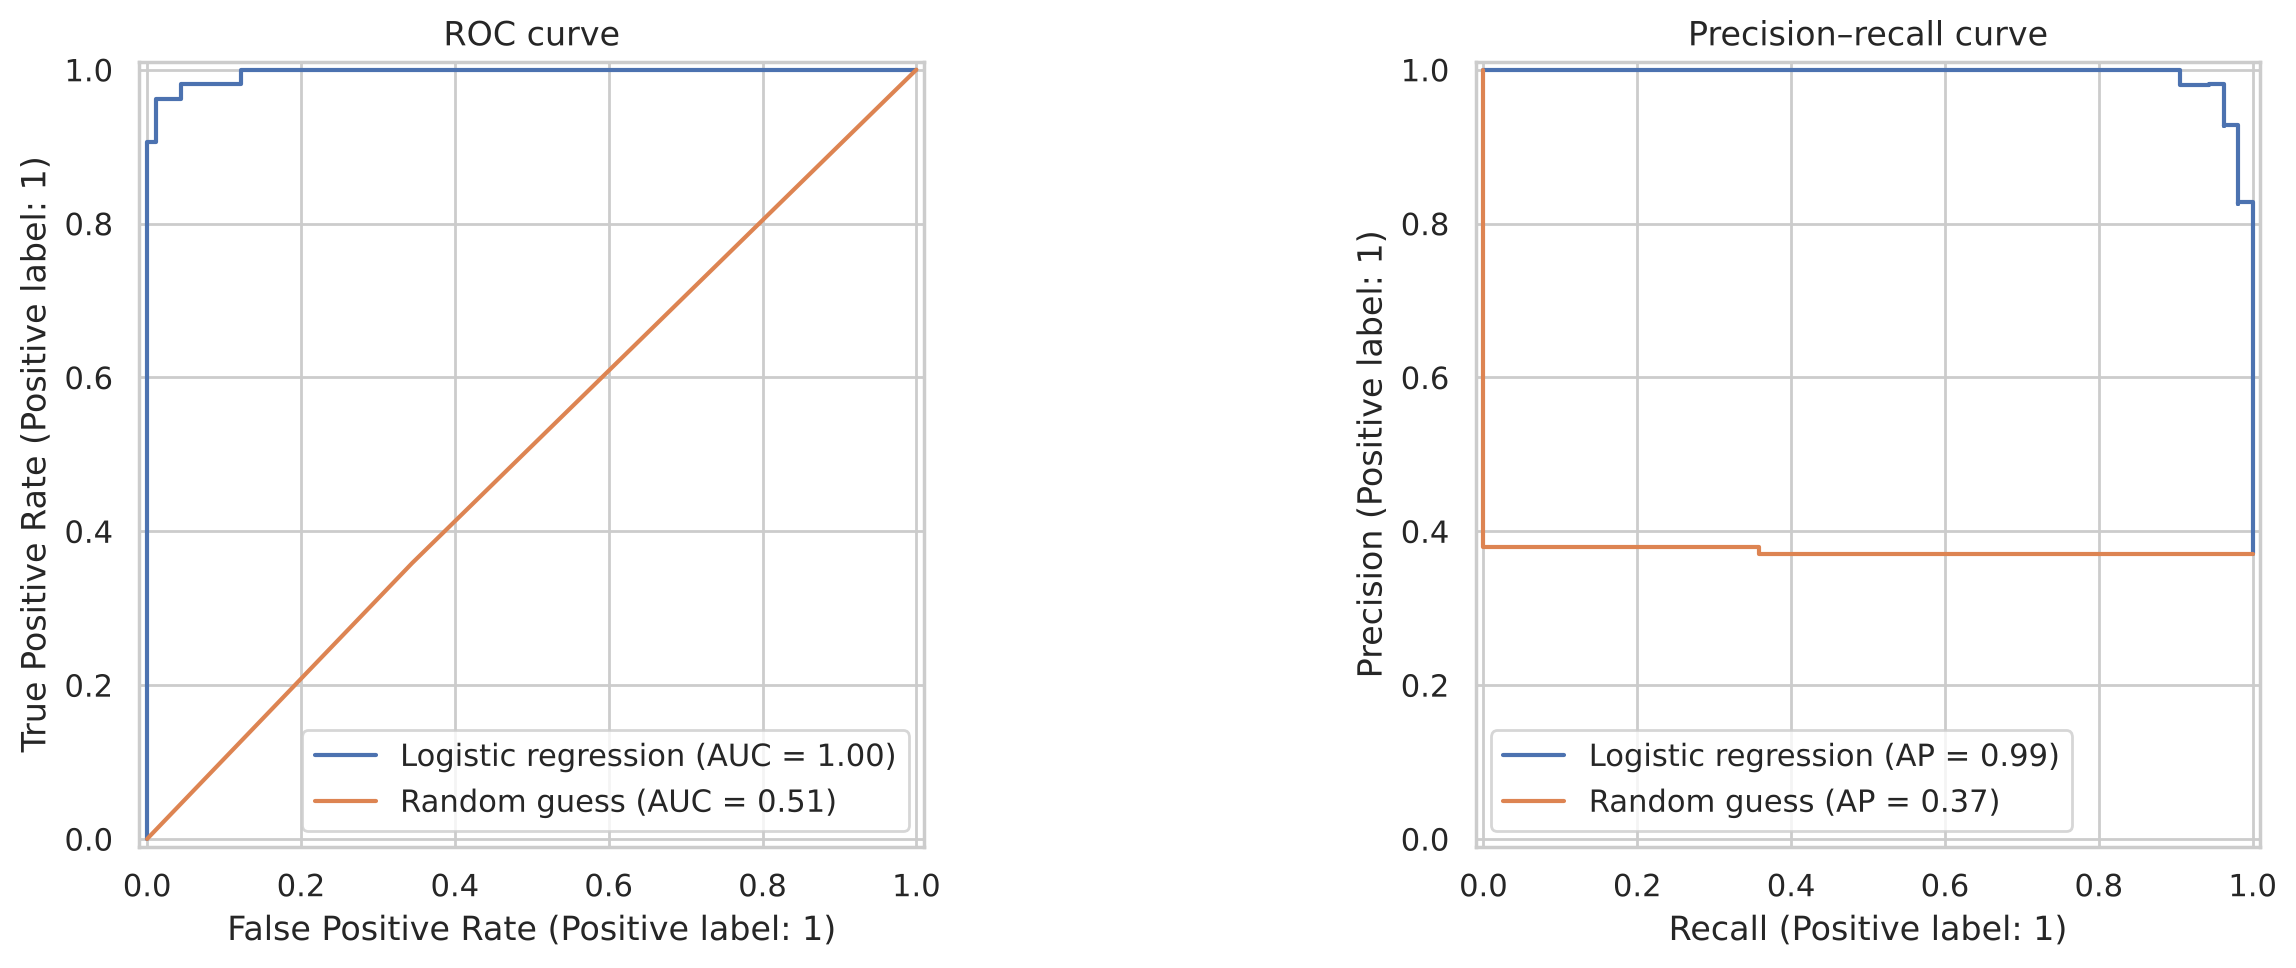

In [11]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="stratified", random_state=0).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_estimator(log_reg, X_test, y_test, ax=axes[0], name="Logistic regression")
RocCurveDisplay.from_estimator(dummy, X_test, y_test, ax=axes[0], name="Random guess")
axes[0].set_title("ROC curve")

PrecisionRecallDisplay.from_estimator(log_reg, X_test, y_test, ax=axes[1], name="Logistic regression")
PrecisionRecallDisplay.from_estimator(dummy, X_test, y_test, ax=axes[1], name="Random guess")
axes[1].set_title("Precision–recall curve")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**ROC یا Precision-Recall؟** وقتی کلاس مثبت **نادر** است، منحنی ROC می‌تواند بیش از حد خوش‌بینانه باشد، چون تعداد زیاد TN باعث می‌شود FPR همیشه کوچک بماند. در این حالت منحنی Precision-Recall و معیار **Average Precision (AP)** گویاتر هستند.

## ۷. منظم‌سازی در رگرسیون لجستیک

`LogisticRegression` در scikit-learn به‌طور پیش‌فرض منظم‌سازی L2 دارد. پارامتر `C` **معکوس** قدرت منظم‌سازی است: `C` کوچک یعنی منظم‌سازی قوی (مدل ساده‌تر) و `C` بزرگ یعنی منظم‌سازی ضعیف. با `l1_ratio=1` (و حل‌کنندهٔ `liblinear` یا `saga`) منظم‌سازی L1 داریم که مثل Lasso بعضی ویژگی‌ها را حذف می‌کند.

</div>

In [12]:
from sklearn.metrics import roc_auc_score

rows = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    model = make_pipeline(StandardScaler(),
                          LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=1000))
    model.fit(X_train, y_train)
    n_used = int(np.sum(model[-1].coef_ != 0))
    rows.append({"C": C, "features used": n_used,
                 "test AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])})
pd.DataFrame(rows).round(4)

,C,features used,test AUC
0,0.001,0,0.5000
1,0.010,3,0.9969
2,0.100,7,0.9987
3,1.000,14,0.9969
4,10.000,21,0.9788


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با منظم‌سازی L1 نسبتاً قوی (`C=0.01`)، مدل فقط از ۳ ویژگی از ۳۰ ویژگی استفاده می‌کند و باز هم AUC بسیار بالایی دارد. اگر منظم‌سازی بیش از حد قوی شود (`C=0.001`)، همهٔ ضرایب صفر می‌شوند و مدل به حدس تصادفی (AUC برابر ۰٫۵) تبدیل می‌شود؛ یعنی کم‌برازش کامل. با منظم‌سازی ضعیف (`C=10`) هم AUC کمی پایین می‌آید که نشانهٔ شروع بیش‌برازش است.

## ۸. طبقه‌بندی چندکلاسه

برای بیش از دو کلاس، رگرسیون لجستیک به **رگرسیون Softmax (چندجمله‌ای)** تعمیم داده می‌شود. برای هر کلاس $k$ یک امتیاز $z_k$ محاسبه می‌شود و تابع Softmax آن‌ها را به احتمال‌هایی با مجموع یک تبدیل می‌کند:

$$\hat{p}_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$$

روش دیگر، **یکی در برابر بقیه (One-vs-Rest)** است: برای هر کلاس یک طبقه‌بند دودویی جداگانه آموزش می‌دهیم. `LogisticRegression` به‌طور پیش‌فرض از Softmax استفاده می‌کند. روی دادهٔ **Wine** (سه نوع شراب، ۱۳ ویژگی شیمیایی) امتحان می‌کنیم:

</div>

In [13]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    wine.data, wine.target, test_size=0.3, stratify=wine.target, random_state=42)

softmax_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
softmax_reg.fit(Xw_train, yw_train)

print(classification_report(yw_test, softmax_reg.predict(Xw_test), target_names=wine.target_names, digits=3))
print("Probabilities for the first test sample:", softmax_reg.predict_proba(Xw_test[:1]).round(3))

              precision    recall  f1-score   support

     class_0      0.947     1.000     0.973        18
     class_1      1.000     0.952     0.976        21
     class_2      1.000     1.000     1.000        15

    accuracy                          0.981        54
   macro avg      0.982     0.984     0.983        54
weighted avg      0.982     0.981     0.982        54

Probabilities for the first test sample: [[0.991 0.009 0.   ]]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در گزارش چندکلاسه:
- **macro avg:** میانگین سادهٔ معیار در همهٔ کلاس‌ها؛ همهٔ کلاس‌ها هم‌وزن‌اند و برای دادهٔ نامتوازن مناسب‌تر است.
- **weighted avg:** میانگین وزنی بر اساس تعداد نمونه‌های هر کلاس.

## جمع‌بندی

- رگرسیون لجستیک با سیگموید، احتمال کلاس مثبت را پیش‌بینی می‌کند و با آنتروپی متقاطع آموزش می‌بیند.
- مرز تصمیم رگرسیون لجستیک خطی است و ضرایب آن قابل تفسیرند.
- accuracy در دادهٔ نامتوازن فریبنده است؛ از Precision، Recall، F1 و ماتریس درهم‌ریختگی استفاده کنید.
- آستانهٔ تصمیم را بر اساس هزینهٔ واقعی خطاها و روی دادهٔ اعتبارسنجی انتخاب کنید.
- AUC کیفیت رتبه‌بندی مدل را مستقل از آستانه می‌سنجد؛ برای کلاس مثبت نادر، منحنی Precision-Recall گویاتر است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. در پیاده‌سازی از صفر، نرخ یادگیری را ۰٫۰۱ و ۱ قرار دهید و نمودار خطا را مقایسه کنید.

۲. کمترین آستانه‌ای را پیدا کنید که Recall روی دادهٔ سرطان ۱۰۰٪ شود. در این آستانه Precision چقدر است؟

۳. با `TunedThresholdClassifierCV` و `scoring="f1"` آستانهٔ بهینه را روی دادهٔ آموزش پیدا کنید و نتیجه را روی دادهٔ آزمون گزارش کنید.

۴. ماتریس درهم‌ریختگی دادهٔ Wine را رسم کنید. کدام کلاس‌ها با هم اشتباه گرفته می‌شوند؟

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** در پیاده‌سازی از صفر، نرخ یادگیری را ۰٫۰۱ و ۱ قرار دهید و نمودار خطا را مقایسه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** کمترین آستانه‌ای را پیدا کنید که Recall روی دادهٔ سرطان ۱۰۰٪ شود. در این آستانه Precision چقدر است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** با `TunedThresholdClassifierCV` و `scoring="f1"` آستانهٔ بهینه را روی دادهٔ آموزش پیدا کنید و نتیجه را روی دادهٔ آزمون گزارش کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** ماتریس درهم‌ریختگی دادهٔ Wine را رسم کنید. کدام کلاس‌ها با هم اشتباه گرفته می‌شوند؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
